# Road Accident Risk Prediction — Exploratory Data Analysis

## Project Overview

This project uses the Kaggle **Predicting Road Accident Risk** dataset to study whether road characteristics, environmental conditions, time-related factors, and previous accident information can be used to predict `accident_risk`.

The purpose of this notebook is to explore and understand the data before model training.

### Main goals of this EDA

1. Load and inspect the training, and test datasets.
2. Check dataset shape, column names, and data types.
3. Identify missing values and duplicate records.
4. Examine the target variable `accident_risk`.
5. Explore numeric feature distributions and correlations.
6. Explore categorical feature distributions.
7. Compare average accident risk across important categories.
8. Check whether train and test datasets have compatible structures.
9. Identify preprocessing decisions needed before regression modeling.

In [35]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Data

The project contains three Kaggle files:

- `train.csv`: contains predictors and the target `accident_risk`
- `test.csv`: contains predictors only and will be used for final prediction
- `sample_submission.csv`: provides the required Kaggle submission format

The training data will be used for EDA, model development, and validation.
The Kaggle test data will be inspected for compatibility but will not be used to evaluate model performance because the target is not provided.

In [36]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
submission_df = pd.read_csv(SUBMISSION_PATH)

print("Data loaded successfully.")

Data loaded successfully.


## 2. Dataset Shapes

First, inspect the number of rows and columns in each file.

In [37]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", submission_df.shape)

Train shape: (517754, 14)
Test shape: (172585, 13)
Sample submission shape: (172585, 2)


## 3. Column Names

Check which variables are available in the training and test datasets.

In [38]:
print("Train columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nSample submission columns:")
print(submission_df.columns.tolist())

Train columns:
['id', 'road_type', 'num_lanes', 'curvature', 'speed_limit', 'lighting', 'weather', 'road_signs_present', 'public_road', 'time_of_day', 'holiday', 'school_season', 'num_reported_accidents', 'accident_risk']

Test columns:
['id', 'road_type', 'num_lanes', 'curvature', 'speed_limit', 'lighting', 'weather', 'road_signs_present', 'public_road', 'time_of_day', 'holiday', 'school_season', 'num_reported_accidents']

Sample submission columns:
['id', 'accident_risk']


## 4. Preview the Data

Inspect the first few observations from each dataset to understand how the variables are stored.

In [39]:
train_df.head()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.06,35,daylight,rainy,False,True,afternoon,False,True,1,0.13
1,1,urban,4,0.99,35,daylight,clear,True,False,evening,True,True,0,0.35
2,2,rural,4,0.63,70,dim,clear,False,True,morning,True,False,2,0.30
3,3,highway,4,0.07,35,dim,rainy,True,True,morning,False,False,1,0.21
4,4,rural,1,0.58,60,daylight,foggy,False,False,evening,True,False,1,0.56


In [40]:
test_df.head()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents
0,517754,highway,2,0.34,45,night,clear,True,True,afternoon,True,True,1
1,517755,urban,3,0.04,45,dim,foggy,True,False,afternoon,True,False,0
2,517756,urban,2,0.59,35,dim,clear,True,False,afternoon,True,True,1
3,517757,rural,4,0.95,35,daylight,rainy,False,False,afternoon,False,False,2
4,517758,highway,2,0.86,35,daylight,clear,True,False,evening,False,True,3


In [41]:
submission_df.head()

,id,accident_risk
0,517754,0.352
1,517755,0.352
2,517756,0.352
3,517757,0.352
4,517758,0.352


## 5. Data Types

Regression models require numeric inputs, so it is important to identify which variables are numeric, categorical, Boolean, or identifiers.

Categorical variables will likely require encoding before model training.

In [42]:
print("Train data types:")
print(train_df.dtypes)

print("\nTest data types:")
print(test_df.dtypes)

Train data types:
id                          int64
road_type                     str
num_lanes                   int64
curvature                 float64
speed_limit                 int64
lighting                      str
weather                       str
road_signs_present           bool
public_road                  bool
time_of_day                   str
holiday                      bool
school_season                bool
num_reported_accidents      int64
accident_risk             float64
dtype: object

Test data types:
id                          int64
road_type                     str
num_lanes                   int64
curvature                 float64
speed_limit                 int64
lighting                      str
weather                       str
road_signs_present           bool
public_road                  bool
time_of_day                   str
holiday                      bool
school_season                bool
num_reported_accidents      int64
dtype: object


## 6. Missing Values

Missing values can affect preprocessing and model training.

Check both the training and test datasets.

In [43]:
train_missing = train_df.isnull().sum()
test_missing = test_df.isnull().sum()

print("Missing values in train:")
print(train_missing)

print("\nMissing values in test:")
print(test_missing)

print("\nTotal missing values in train:", train_df.isnull().sum().sum())
print("Total missing values in test:", test_df.isnull().sum().sum())

Missing values in train:
id                        0
road_type                 0
num_lanes                 0
curvature                 0
speed_limit               0
lighting                  0
weather                   0
road_signs_present        0
public_road               0
time_of_day               0
holiday                   0
school_season             0
num_reported_accidents    0
accident_risk             0
dtype: int64

Missing values in test:
id                        0
road_type                 0
num_lanes                 0
curvature                 0
speed_limit               0
lighting                  0
weather                   0
road_signs_present        0
public_road               0
time_of_day               0
holiday                   0
school_season             0
num_reported_accidents    0
dtype: int64

Total missing values in train: 0
Total missing values in test: 0


## 7. Duplicate Records

Duplicate rows can distort summaries and model training, so check whether exact duplicates are present.

In [44]:
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test:", test_df.duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0


## 8. Training vs. Test Feature Compatibility

The model will eventually be trained using `train.csv` and applied to `test.csv`.

Therefore, the predictor columns should match between the two datasets.

In [45]:
TARGET = "accident_risk"

train_features = set(train_df.columns) - {TARGET}
test_features = set(test_df.columns)

print("Same feature columns:", train_features == test_features)

print("\nFeatures only in train:")
print(train_features - test_features)

print("\nFeatures only in test:")
print(test_features - train_features)

Same feature columns: True

Features only in train:
set()

Features only in test:
set()


## 9. Target Variable: `accident_risk`

The target variable is the outcome the regression model will predict.

This section examines its range, center, spread, and distribution.

In [46]:
train_df[TARGET].describe()

count    517754.000000
mean          0.352377
std           0.166417
min           0.000000
25%           0.230000
50%           0.340000
75%           0.460000
max           1.000000
Name: accident_risk, dtype: float64

## 10. Distribution of Accident Risk

The summary statistics show the center and range of the target, but they do not show the shape of the distribution.

A histogram helps visualize whether accident-risk values are concentrated in certain ranges, approximately symmetric, or skewed.

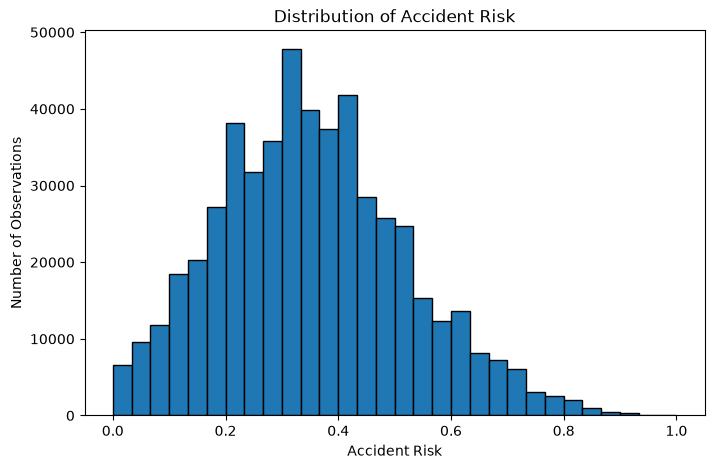

In [47]:
plt.figure(figsize=(8, 5))

plt.hist(
    train_df[TARGET],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Accident Risk")
plt.ylabel("Number of Observations")
plt.title("Distribution of Accident Risk")

plt.show()

### Interpretation

The histogram shows how `accident_risk` values are distributed across the training dataset.

Most observations appear to be concentrated in the lower-to-middle portion of the 0–1 range, while fewer observations occur near the highest risk values.

This helps us understand the target distribution before fitting a regression model.

## 11. Numeric Feature Summary

Next, inspect the numeric predictors to understand their ranges, averages, variability, and possible unusual values.

This helps identify variables that may require additional checking before modeling.

In [48]:
numeric_predictors = [
    "num_lanes",
    "curvature",
    "speed_limit",
    "num_reported_accidents"
]

train_df[numeric_predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
num_lanes,517754.0,2.491511,1.120434,1.0,1.00,2.00,3.00,4.0
curvature,517754.0,0.488719,0.272563,0.0,0.26,0.51,0.71,1.0
speed_limit,517754.0,46.112575,15.788521,25.0,35.00,45.00,60.00,70.0
num_reported_accidents,517754.0,1.187970,0.895961,0.0,1.00,1.00,2.00,7.0


### Interpretation

The numeric predictors show reasonable ranges in the available data.

- `num_lanes` ranges from 1 to 4.
- `curvature` ranges from 0 to 1.
- `speed_limit` ranges from 25 to 70.
- `num_reported_accidents` ranges from 0 to 7.

No obviously impossible numeric values are visible from these summary statistics.

This suggests that the numeric predictors are suitable for further exploratory analysis.

## 12. Numeric Correlation with Accident Risk

Pearson correlation is used to examine the direction and strength of the linear relationship between each numeric predictor and `accident_risk`.

A positive correlation means that accident risk tends to increase as the predictor increases.

A negative correlation means that accident risk tends to decrease as the predictor increases.

A correlation value closer to zero indicates a weaker linear relationship.

Correlation is used here as an exploratory measure and does not imply causation.

In [49]:
correlation_cols = numeric_predictors + [TARGET]

correlations = (
    train_df[correlation_cols]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

correlations

curvature                 0.543946
speed_limit               0.430898
num_reported_accidents    0.213891
num_lanes                -0.006003
Name: accident_risk, dtype: float64

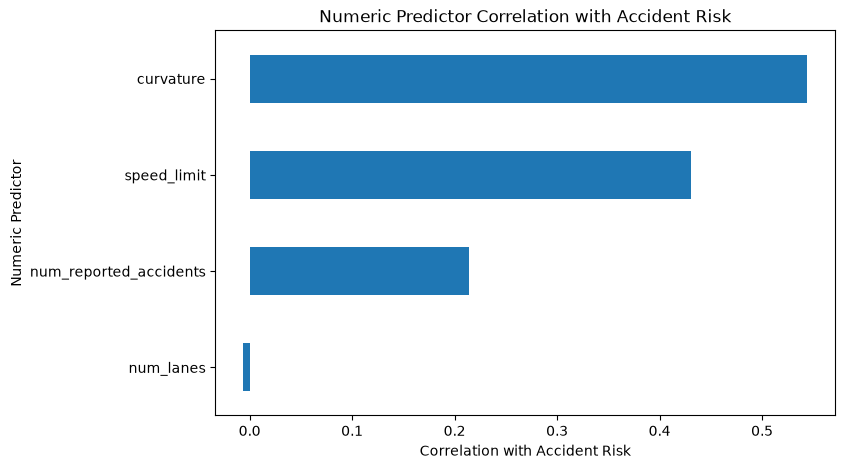

In [50]:
plt.figure(figsize=(8, 5))

correlations.sort_values().plot(kind="barh")

plt.xlabel("Correlation with Accident Risk")
plt.ylabel("Numeric Predictor")
plt.title("Numeric Predictor Correlation with Accident Risk")

plt.show()

### Interpretation

Among the numeric predictors, `curvature` has the strongest positive linear relationship with `accident_risk` (r ≈ 0.544).

`speed_limit` also shows a moderate positive relationship with accident risk (r ≈ 0.431).

`num_reported_accidents` has a weaker positive relationship with accident risk (r ≈ 0.214).

`num_lanes` has almost no linear relationship with accident risk (r ≈ -0.006).

These correlations provide useful exploratory information, but they do not imply causation. A weak individual correlation also does not automatically mean that a predictor should be removed, because it may still contribute useful information when combined with other variables in Multiple Linear Regression.

## 13. Categorical and Boolean Predictors

The dataset also contains categorical and Boolean predictors.

These variables represent groups or conditions rather than continuous numeric measurements, so they should be reviewed separately.

Categorical predictors will later require encoding before they can be used in Multiple Linear Regression.

In [51]:
categorical_cols = [
    "road_type",
    "lighting",
    "weather",
    "time_of_day"
]

boolean_cols = [
    "road_signs_present",
    "public_road",
    "holiday",
    "school_season"
]

print("Categorical predictors:")
print(categorical_cols)

print("\nBoolean predictors:")
print(boolean_cols)

Categorical predictors:
['road_type', 'lighting', 'weather', 'time_of_day']

Boolean predictors:
['road_signs_present', 'public_road', 'holiday', 'school_season']


### Interpretation

The dataset contains four categorical predictors and four Boolean predictors.

These variables will be examined further for their distributions and relationships with `accident_risk`.

Categorical predictors will require encoding before Multiple Linear Regression.

## 14. Categorical Feature Analysis

Categorical predictors are reviewed in two ways:

1. Category frequencies are checked to identify rare or strongly imbalanced categories.
2. Average `accident_risk` is compared across categories to explore potential relationships with the target.

These analyses are exploratory and do not imply causation.

In [56]:
for col in categorical_cols:
    print(f"\n--- {col}: Accident Risk Summary ---")

    summary = (
        train_df
        .groupby(col)[TARGET]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    display(summary)


--- road_type: Accident Risk Summary ---


,count,mean,median
road_type,,,
urban,171363,0.357456,0.35
rural,172719,0.349997,0.34
highway,173672,0.349734,0.34



--- lighting: Accident Risk Summary ---


,count,mean,median
lighting,,,
night,155913,0.470467,0.45
daylight,178015,0.302923,0.30
dim,183826,0.300109,0.30



--- weather: Accident Risk Summary ---


,count,mean,median
weather,,,
foggy,181463,0.386305,0.37
rainy,156985,0.361494,0.35
clear,179306,0.310060,0.30



--- time_of_day: Accident Risk Summary ---


,count,mean,median
time_of_day,,,
evening,172837,0.354736,0.34
afternoon,171507,0.351428,0.34
morning,173410,0.350966,0.34


### Interpretation

The categorical predictors are generally well represented across their categories, with no extremely rare groups.

- `road_type` is nearly evenly distributed across urban, rural, and highway observations. Average accident risk is slightly higher for urban roads, but the differences across road types are small.
- `lighting` shows a clear difference in accident risk. Night conditions have a substantially higher average accident risk than daylight or dim conditions.
- `weather` also shows noticeable differences. Foggy conditions have the highest average accident risk, followed by rainy conditions, while clear weather has the lowest average risk.
- `time_of_day` shows very similar average accident risk across morning, afternoon, and evening, suggesting little difference when this variable is examined by itself.

These results suggest that `lighting` and `weather` may provide stronger predictive information than `road_type` or `time_of_day` when considered individually.

These comparisons are exploratory and do not imply causation.

## 15. Boolean Feature Analysis

Boolean predictors are examined by comparing the number of observations and the average and median `accident_risk` between `True` and `False` groups.

This helps determine whether conditions such as road signs, public-road status, holidays, or school season are associated with different levels of accident risk.

These comparisons are exploratory and do not imply causation.

In [ ]:
for col in boolean_cols:
    print(f"\n--- {col}: Accident Risk Summary ---")

    summary = (
        train_df
        .groupby(col)[TARGET]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    display(summary)


--- road_signs_present: Accident Risk Summary ---


,count,mean,median
road_signs_present,,,
True,258465,0.352482,0.34
False,259289,0.352273,0.34



--- public_road: Accident Risk Summary ---


,count,mean,median
public_road,,,
True,260045,0.357518,0.35
False,257709,0.347190,0.34



--- holiday: Accident Risk Summary ---


,count,mean,median
holiday,,,
True,260688,0.360827,0.35
False,257066,0.343809,0.33



--- school_season: Accident Risk Summary ---


,count,mean,median
school_season,,,
False,260164,0.352539,0.34
True,257590,0.352214,0.34


: 

### Interpretation

The Boolean predictors are generally well balanced between `True` and `False`, and most show only small differences in average `accident_risk`.

- `road_signs_present` shows almost no difference in average accident risk between the `True` and `False` groups.
- `public_road` shows a slightly higher average accident risk when the value is `True`.
- `holiday` shows the clearest difference among the Boolean predictors, with higher average accident risk for holiday observations.
- `school_season` shows almost no difference between the `True` and `False` groups.

These results provide an initial view of how the Boolean predictors relate to accident risk. Variables with small group differences may still contribute useful information when combined with other predictors in Multiple Linear Regression.

## 15. Train/Test Category Compatibility

The training and test datasets already have matching predictor columns.

The next check is whether categorical and Boolean predictors also contain compatible values.

If the test dataset contains a category that never appears in the training data, the preprocessing pipeline must be able to handle that unseen category.

In [54]:
for col in categorical_cols:
    train_values = set(train_df[col].dropna().unique())
    test_values = set(test_df[col].dropna().unique())

    print(f"\n--- {col} ---")
    print("Only in train:", train_values - test_values)
    print("Only in test:", test_values - train_values)

for col in boolean_cols:
    train_values = set(train_df[col].dropna().unique())
    test_values = set(test_df[col].dropna().unique())

    print(f"\n--- {col} ---")
    print("Only in train:", train_values - test_values)
    print("Only in test:", test_values - train_values)


--- road_type ---
Only in train: set()
Only in test: set()

--- lighting ---
Only in train: set()
Only in test: set()

--- weather ---
Only in train: set()
Only in test: set()

--- time_of_day ---
Only in train: set()
Only in test: set()

--- road_signs_present ---
Only in train: set()
Only in test: set()

--- public_road ---
Only in train: set()
Only in test: set()

--- holiday ---
Only in train: set()
Only in test: set()

--- school_season ---
Only in train: set()
Only in test: set()


### Interpretation

The training and test datasets contain compatible values for all categorical and Boolean predictors.

No categories appear exclusively in the training data or exclusively in the test data.

This means the model will not encounter unexpected category values when the final pipeline is applied to the Kaggle test dataset.

## 16. Preliminary Preprocessing Decisions

Based on the exploratory analysis, several preprocessing decisions can be identified before regression modeling.

- `id` will be excluded from the predictor set because it functions as an observation identifier.
- Numeric predictors can be used directly after confirming that their ranges are reasonable.
- Categorical predictors such as `road_type`, `lighting`, `weather`, and `time_of_day` will require encoding before Multiple Linear Regression.
- Boolean predictors can be converted to numeric form during preprocessing.
- No missing-value imputation is currently required because no missing values were identified.
- Train and test datasets contain compatible predictor columns and category values.
- Predictors will not be removed solely because they show weak individual relationships with `accident_risk`; their contribution will be evaluated within the full regression model.

## 17. Audit & Split Summary

### Dataset Overview
- `train.csv`: **517,754 rows × 14 columns**
- `test.csv`: **172,585 rows × 13 columns**
- Target: **`accident_risk`**
- Target type: **continuous numeric variable (0–1)**
- Problem type: **Supervised Regression**

### Data Quality
- No missing values
- No duplicate rows
- Train and test contain compatible predictor columns
- Train and test contain compatible category values
- `id` is unique and will be treated as an identifier rather than a predictor

### Key EDA Findings

**Numeric predictors**
- `curvature`: strongest positive correlation with accident risk (**r ≈ 0.544**)
- `speed_limit`: moderate positive correlation (**r ≈ 0.431**)
- `num_reported_accidents`: weaker positive correlation (**r ≈ 0.214**)
- `num_lanes`: almost no individual linear correlation (**r ≈ -0.006**)

**Categorical predictors**
- `lighting`: noticeable differences; **night** has the highest average risk
- `weather`: noticeable differences; **foggy** has the highest average risk and **clear** the lowest
- `road_type`: relatively small differences
- `time_of_day`: very small differences

**Boolean predictors**
- `holiday`: clearest difference in average risk
- `public_road`: small difference
- `road_signs_present`: very small difference
- `school_season`: very small difference

### Preliminary Preprocessing Decisions
- Exclude `id` from model predictors
- Encode categorical variables
- Convert Boolean variables to model-ready numeric form
- No missing-value imputation is currently required
- Weak individual relationships will not automatically cause a predictor to be removed

### Train / Validation Split
- **Training set:** 414,203 observations (~80%)
- **Validation set:** 103,551 observations (~20%)
- Training mean `accident_risk`: **0.352605**
- Validation mean `accident_risk`: **0.351466**
- Both sets have median `accident_risk` of **0.34**

### Phase 1 Outcome
The dataset appears clean, compatible, and suitable for regression modeling.

The training and validation sets have similar target distributions, so the project is ready to move to **Phase 2 — FIT: preprocessing, baseline model, and Multiple Linear Regression**.